<a href="https://colab.research.google.com/github/yosly89ba-star/Proyecto_grupo1CCI/blob/main/notebooks/S56_red_con_mis_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Datos con IA Aplicada · DESPUÉS de las sesiones 5 y 6
## Tarea 4  · Una red neuronal con TUS datos

**Docente:** Doris Elena Campo Duarte · Escuela de Posgrado, Universidad Peruana Unión

**Qué vas a hacer:** lo mismo del laboratorio 1 (dos redes, una sin freno y otra con freno), pero con los datos de tu investigación. Y un paso más: vas a probar cuatro redes distintas, elegir la mejor **con los quices** y solo al final presentarle el examen final, junto a Elastic Net y Random Forest.

**¿Por qué es un poco más difícil?** Porque tus datos no vienen limpios como los de la clase: pueden tener columnas de texto, celdas vacías y otra cantidad de casos. El cuaderno se encarga de eso; tú solo cambias cuatro líneas.

**Son cuatro celdas.** Ejecútalas en orden con **Ctrl + Enter**. Tarda unos 3 a 5 minutos en total.

### Antes de empezar
1. Archivo → **Guardar una copia en Drive**.
2. Prepara tu archivo **CSV**: una fila por caso y una columna por variable. **Sin nombres, DNI ni nada que identifique a personas.**
3. Súbelo: clic en el ícono de carpeta 📁 de la izquierda → ícono de subir → elige tu archivo. Aparecerá como `/content/tu_archivo.csv`.
4. Lo que quieras predecir debe tener **dos resultados** (sí/no, aprobó/no aprobó, desertó/no desertó). Si tu variable es un número, primero conviértela en dos grupos (por ejemplo, «nota ≥ 14» y «nota < 14»).

**IA responsable:** usa solo datos anonimizados y autorizados. El examen final se mira una sola vez, al final.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



## R1 · Cargar y preparar tus datos

**¿Para qué sirve?** Lee tu archivo, convierte lo que quieres predecir en 1 (sí) y 0 (no), y separa tus casos en tres grupos: para estudiar, para los quices y para el examen final.

**Paso a paso:**
1. Cambia **solo** las cuatro líneas que están entre las líneas de `=====`:
   - `ARCHIVO`: la ruta de tu archivo. Clic derecho sobre el archivo en el panel → **Copiar ruta** → pégala entre las comillas.
   - `RESPUESTA`: el nombre exacto de la columna que quieres predecir, tal como aparece en tu archivo.
   - `POSITIVO`: el valor que quieres detectar, escrito igual que en tu archivo (por ejemplo `"Desertó"`, `"Maligno"` o `"1"`).
   - `EXCLUIR`: columnas que **no** deben usarse, como códigos, nombres o fechas. Si no tienes, deja `[]`.
2. Ejecuta la celda.

📖 **Palabras nuevas:**
- **Variable de texto convertida en 0/1:** una red solo entiende números. Si tienes una columna «sede» con Lima, Juliaca y Tarapoto, el cuaderno crea columnas de 0 y 1 para cada sede. *Ejemplo:* «¿es de Juliaca? 1 = sí, 0 = no».
- **Rellenar vacíos:** si a un caso le falta un dato, se completa con la mediana (el valor del medio) de ese dato. *Ejemplo:* si falta la edad, se pone la edad típica del grupo.

| Lo que ves en el código | Qué significa, en simple |
|---|---|
| `ARCHIVO, RESPUESTA, POSITIVO, EXCLUIR` | Las cuatro líneas que tú cambias. |
| `pd.read_csv(ARCHIVO)` | Lee tu archivo. |
| `raise ValueError(...)` | Si escribiste mal el valor POSITIVO, te avisa y te muestra los valores que sí existen. |
| `pd.get_dummies(...)` | Convierte las columnas de texto en columnas de 0 y 1. |
| `train_test_split(...)` | Separa el examen final (25 %) y luego los quices (25 % de lo que queda). |
| `SimpleImputer(strategy="median")` | Rellena los vacíos con la mediana, calculada solo con los casos de estudio. |
| `StandardScaler()` | Pone todas las variables en la misma escala, también solo con los casos de estudio. |

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
SEMILLA = 2026

# ======== CAMBIA SOLO ESTAS CUATRO LÍNEAS ========
ARCHIVO   = "/content/drive/MyDrive/Colab Notebooks/anemia_modelo.csv"
RESPUESTA = "anemia"
POSITIVO  = "1"
EXCLUIR   = ["anio", "hb_ajustada", "anemia_oms", "hierro_7d", "z_implausible"]
# =================================================

df = pd.read_csv(ARCHIVO).dropna(subset=[RESPUESTA])
if str(POSITIVO) not in df[RESPUESTA].astype(str).unique():
    raise ValueError(f"No encuentro «{POSITIVO}» en {RESPUESTA}. Sus valores son: "
                     f"{list(df[RESPUESTA].astype(str).unique()[:10])}")
y = (df[RESPUESTA].astype(str) == str(POSITIVO)).astype(int)
quitar = [RESPUESTA] + [c for c in EXCLUIR if c in df.columns]
X = pd.get_dummies(df.drop(columns=quitar), drop_first=True, dtype=float)
print(f"{len(df)} casos · {X.shape[1]} variables · {y.sum()} casos «{POSITIVO}» ({y.mean():.0%})")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
X_ent, X_val, y_ent, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEMILLA)

relleno = SimpleImputer(strategy="median").fit(X_ent)
escala = StandardScaler().fit(relleno.transform(X_ent))
prep = lambda A: escala.transform(relleno.transform(A))
X_ent_s, X_val_s, X_test_s, X_train_s = prep(X_ent), prep(X_val), prep(X_test), prep(X_train)
print("Estudia:", len(y_ent), "| Quices:", len(y_val), "| Examen final:", len(y_test))

35974 casos · 57 variables · 12630 casos «1» (35%)
Estudia: 20235 | Quices: 6745 | Examen final: 8994


**Si todo va bien, verás:** dos líneas. Por ejemplo, con los datos de la clase: «569 casos · 32 variables · 212 casos «Maligno» (37%)» y «Estudia: 319 | Quices: 107 | Examen final: 143».

**Si sale un error:** lee la última línea. Si dice «No encuentro…», corrige `POSITIVO` con uno de los valores que te muestra. Si dice `KeyError`, el nombre de `RESPUESTA` o de `EXCLUIR` no está escrito igual que en tu archivo (revisa mayúsculas, tildes y espacios). Si dice `FileNotFoundError`, revisa la ruta de `ARCHIVO`.

✍️ **Anota:** ¿cuántos casos y variables tienes? ¿Qué porcentaje son «positivos»? Si es menos del 10 %, tus datos están **desbalanceados**: tenlo en cuenta en tu artículo.

**Si algo no queda claro** (cópialo completo y pégalo en tu asistente de IA si algo no queda claro):

```text
Estoy preparando mis datos para una red neuronal en Google Colab. Explícame en
lenguaje sencillo qué hace este código y qué significa el resultado que pego al final.

[pega aquí el código de la celda R1]

Resultado:
[pega aquí lo que salió]
```

## R2 · Dos redes con tus datos: sin freno y con freno

**¿Para qué sirve?** Es la misma celda L1.2 de la clase, ahora con tus datos. Vas a ver si, con tus casos, la red grande sin freno también memoriza.

**Paso a paso:** ejecuta la celda (tarda uno o dos minutos) y mira los dos gráficos.

| Lo que ves en el código | Qué significa, en simple |
|---|---|
| `def entrenar(neuronas, freno, dropout, tasa)` | La receta para armar y entrenar una red. Ahora también se puede cambiar cuánto apaga el dropout y la tasa de aprendizaje. |
| `keras.Input(shape=(X_ent_s.shape[1],))` | La entrada: tantas neuronas como variables tienes. |
| `keras.optimizers.Adam(tasa)` | La tasa de aprendizaje: qué tan grande es cada corrección de los pesos. |
| `entrenar([128, 64], freno=False)` | Red grande sin freno. |
| `entrenar([16, 8], freno=True)` | Red pequeña con dropout y parada temprana. |

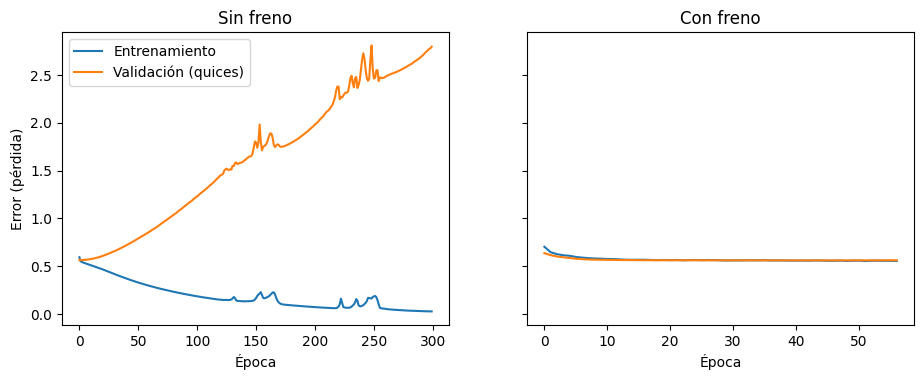

Sin freno: mejor época 3 de 300
Con freno: se detuvo en la época 57


In [4]:
def entrenar(neuronas, freno, dropout=0.3, tasa=0.001):
    keras.utils.set_random_seed(SEMILLA)
    capas = [keras.Input(shape=(X_ent_s.shape[1],))]
    for n in neuronas:
        capas.append(keras.layers.Dense(n, activation="relu"))
        if freno: capas.append(keras.layers.Dropout(dropout))          # freno 1
    capas.append(keras.layers.Dense(1, activation="sigmoid"))
    red = keras.Sequential(capas)
    red.compile(optimizer=keras.optimizers.Adam(tasa), loss="binary_crossentropy")
    parar = [keras.callbacks.EarlyStopping(patience=20,                  # freno 2
             restore_best_weights=True)] if freno else []
    h = red.fit(X_ent_s, y_ent, validation_data=(X_val_s, y_val), epochs=300,
                batch_size=256, verbose=0, callbacks=parar)
    return red, h

red_sin, h_sin = entrenar([128, 64], freno=False)
red_con, h_con = entrenar([16, 8], freno=True)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for eje, h, titulo in [(ejes[0], h_sin, "Sin freno"), (ejes[1], h_con, "Con freno")]:
    eje.plot(h.history["loss"], label="Entrenamiento")
    eje.plot(h.history["val_loss"], label="Validación (quices)")
    eje.set_title(titulo); eje.set_xlabel("Época")
ejes[0].set_ylabel("Error (pérdida)"); ejes[0].legend(); plt.show()
print("Sin freno: mejor época", int(np.argmin(h_sin.history["val_loss"])) + 1, "de 300")
print("Con freno: se detuvo en la época", len(h_con.history["loss"]))

**Si todo va bien, verás:** dos gráficos y dos líneas de texto. En el de la izquierda, mira si la línea naranja (quices) baja y después sube: eso es memorizar.

✍️ **Anota:** ¿en qué época empezó a memorizar la red sin freno? ¿En qué época se detuvo la red con freno? ¿Tu gráfico se parece al de la clase?

## R3 · Tu experimento: cuatro redes, elegidas con los quices

**¿Para qué sirve?** Esta es la parte nueva. En lugar de quedarte con la primera red, pruebas cuatro y eliges la mejor **mirando la nota de los quices**, no la del examen final. Así el examen final sigue siendo honesto.

**¿Por qué así?** Si eligieras la red mirando el examen final, sería como estudiar con las preguntas del examen: la nota ya no diría cuánto sabe de verdad.

📖 **Palabras nuevas:**
- **Hiperparámetros:** los ajustes que decides tú antes de entrenar: cuántas neuronas, cuánto dropout, qué tasa de aprendizaje. *Ejemplo:* como la temperatura del horno antes de hornear.
- **Tasa de aprendizaje:** qué tan grande es cada corrección de los pesos. Muy grande, la red se pasa de largo; muy pequeña, tarda muchísimo.

**Paso a paso:**
1. Ejecuta la celda tal como está (tarda dos o tres minutos).
2. Si quieres, cambia los números de alguna línea de `pruebas` y vuelve a ejecutarla. Por ejemplo, `[64, 32]` neuronas o un dropout de `0.4`.

| Lo que ves en el código | Qué significa, en simple |
|---|---|
| `pruebas = [...]` | Las cuatro redes que vas a comparar. Cada línea es una red. |
| `"neuronas": [16, 8]` | Dos capas: la primera con 16 neuronas y la segunda con 8. |
| `"dropout": 0.3` | Apaga al azar el 30 % de las neuronas en cada paso. |
| `"tasa": 0.001` | La tasa de aprendizaje. |
| `roc_auc_score(y_val, ...)` | La nota (AUC) en los quices: la que usamos para elegir. |
| `idxmax()` | Busca la red con la nota más alta en los quices. |

In [5]:
pruebas = [   # cada línea es una red distinta; puedes cambiar los números
    {"neuronas": [16, 8],  "dropout": 0.3, "tasa": 0.001},
    {"neuronas": [32, 16], "dropout": 0.3, "tasa": 0.001},
    {"neuronas": [16, 8],  "dropout": 0.5, "tasa": 0.001},
    {"neuronas": [8],      "dropout": 0.2, "tasa": 0.01},
]
filas = []
for i, p in enumerate(pruebas, 1):
    red, h = entrenar(p["neuronas"], True, p["dropout"], p["tasa"])
    nota = roc_auc_score(y_val, red.predict(X_val_s, verbose=0).ravel())   # nota en quices
    filas.append({"Prueba": i, "Neuronas": p["neuronas"], "Dropout": p["dropout"],
                  "Tasa": p["tasa"], "Épocas": len(h.history["loss"]),
                  "AUC en quices": round(nota, 3)})
resultados = pd.DataFrame(filas)
resultados["Total de neuronas"] = [sum(p["neuronas"]) for p in pruebas]
# la mejor nota en los quices; si hay empate, la más sencilla (parsimonia)
orden = resultados.sort_values(["AUC en quices", "Total de neuronas"], ascending=[False, True])
elegida = pruebas[int(orden.index[0])]
print(resultados.drop(columns="Total de neuronas").to_string(index=False))
print("\nRed elegida con los quices (no con el examen):", elegida)

 Prueba Neuronas  Dropout  Tasa  Épocas  AUC en quices
      1  [16, 8]      0.3 0.001      57          0.743
      2 [32, 16]      0.3 0.001      38          0.744
      3  [16, 8]      0.5 0.001     111          0.742
      4      [8]      0.2 0.010      32          0.744

Red elegida con los quices (no con el examen): {'neuronas': [8], 'dropout': 0.2, 'tasa': 0.01}


**Si todo va bien, verás:** una tabla con cuatro filas (una por red), su nota en los quices y cuántas épocas entrenó. Debajo, la red elegida. **Si varias empatan** (con los datos de la clase, las cuatro sacan 1,0), el cuaderno elige la más sencilla, la de menos neuronas: eso es la parsimonia.

✍️ **Piensa:** ¿las cuatro notas son muy distintas o casi iguales? Si son casi iguales, ¿cuál elegirías por **parsimonia** (la más sencilla)?

## R4 · El examen final: tu red frente a Elastic Net y Random Forest

**¿Para qué sirve?** Ahora sí, una sola vez, todos presentan el examen final con los mismos casos: las dos redes de R2, la red elegida en R3, Elastic Net y Random Forest. Además se cuentan los dos tipos de error.

| Lo que ves en el código | Qué significa, en simple |
|---|---|
| `LogisticRegression(penalty="elasticnet", ...)` | Elastic Net, el modelo que elegimos en la sesión 4. |
| `RandomForestClassifier(n_estimators=300)` | Random Forest con 300 árboles. |
| `confusion_matrix(...)` | Cuenta los positivos que no se detectaron y las falsas alarmas, con el umbral 0,5. |
| `roc_auc_score(y_test, p)` | La nota (AUC) en el examen final. |

In [6]:
red_mejor, _ = entrenar(elegida["neuronas"], True, elegida["dropout"], elegida["tasa"])
en = LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=0.5,
                        max_iter=5000).fit(X_train_s, y_train)
rf = RandomForestClassifier(n_estimators=300, random_state=SEMILLA).fit(X_train_s, y_train)

probas = {"Elastic Net": en.predict_proba(X_test_s)[:, 1],
          "Random Forest": rf.predict_proba(X_test_s)[:, 1],
          "Red sin freno": red_sin.predict(X_test_s, verbose=0).ravel(),
          "Red con freno": red_con.predict(X_test_s, verbose=0).ravel(),
          "Red elegida": red_mejor.predict(X_test_s, verbose=0).ravel()}
filas = []
for nombre, p in probas.items():
    tn, fp, fn, tp = confusion_matrix(y_test, (p >= 0.5).astype(int), labels=[0, 1]).ravel()
    filas.append({"Modelo": nombre, "AUC en examen final": round(roc_auc_score(y_test, p), 3),
                  f"«{POSITIVO}» no detectados": fn, "Falsas alarmas": fp})
final = pd.DataFrame(filas)
print(final.to_string(index=False))
print(f"\nEn el examen hay {int(y_test.sum())} casos «{POSITIVO}» y {int((y_test == 0).sum())} que no lo son.")

       Modelo  AUC en examen final  «1» no detectados  Falsas alarmas
  Elastic Net                0.755               1717             728
Random Forest                0.753               1722             782
Red sin freno                0.645               1769            1421
Red con freno                0.752               1765             714
  Red elegida                0.751               1887             616

En el examen hay 3158 casos «1» y 5836 que no lo son.


**Si todo va bien, verás:** una tabla con cinco modelos, su AUC en el examen final, cuántos casos positivos no se detectaron y cuántas falsas alarmas hubo.

✍️ **Para tu artículo:** ¿la red le gana a Elastic Net por más que la variación que viste en tu tabla de la tarea 1 (el ±)? Si no, ¿con cuál te quedas y por qué? ¿Qué error es más grave en tu tema: un positivo no detectado o una falsa alarma?

**Llévalo al DESPUÉS:** copia la tabla de R3 y la de R4 en el documento del DESPUÉS, en la tarea 4.

**Para interpretar tus resultados** (cópialo completo y pégalo en tu asistente de IA si algo no queda claro):

```text
Estoy comparando varios modelos predictivos con mis datos de investigación de toxicidad en peces (alta frente a baja toxicidad LC50). Pego al final la tabla con el AUC en el examen final y los errores de cada modelo. Ayúdame a interpretarla en lenguaje sencillo:

1. ¿Hay un modelo claramente mejor o están estadísticamente empatados?
2. ¿Qué significan físicamente los errores («Alta» no detectados vs. Falsas alarmas) en este contexto?
3. ¿Qué conclusiones NO debería extraer para evitar sobreinterpretar los resultados?

Resultados del Examen Final:
Modelo          AUC en examen final    «Alta» no detectados    Falsas alarmas
Elastic Net     0.878                  20                      20
Random Forest   0.906                  18                      18
Red sin freno   0.885                  20                      23
Red con freno   0.879                  18                      27
Red elegida     0.879                  18                      27

(En el examen hay 114 casos «Alta» de toxicidad y 113 que no lo son)
```

1. ¿Hay un modelo claramente mejor o están estadísticamente empatados?
Random Forest obtuvo la mejor métrica absoluta (0.906 de AUC).
Sin embargo, la Red elegida (0.879) y Elastic Net (0.878) están extremadamente cerca.
Se puede concluir un empate técnico entre los tres modelos, aunque por simplicidad operativa y parsimonia, Elastic Net destaca como una opción excelente al ser un modelo lineal sumamente sencillo con casi la misma precisión.
2. ¿Qué significan físicamente los errores en este contexto?
«Alta» no detectados (Falsos Negativos): Sustancias químicas altamente tóxicas clasificadas incorrectamente como "seguras". Este es el error más crítico, ya que liberarlas al agua provocaría la muerte de poblaciones de peces.
Falsas alarmas (Falsos Positivos): Sustancias inocuas marcadas erróneamente como peligrosas. Esto causaría pérdidas económicas por descartar sustancias útiles o realizar pruebas de laboratorio innecesarias.
3. ¿Qué conclusiones NO deberías extraer para evitar sobreinterpretar?
No asumas que las Redes Neuronales siempre son mejores: En este problema, un algoritmo de árboles clásico (Random Forest) superó a la red neuronal compleja.
No consideres el modelo infalible: Un AUC de 0.90 es excelente, pero el modelo de Random Forest todavía falló en detectar 18 químicos altamente tóxicos y generó 18 falsas alarmas.

## Para cerrar

✍️ **En una frase:** con tus datos, ¿vale la pena una red neuronal o te quedas con un modelo más sencillo?

Con mis datos no vale la pena una red neuronal: empata con Elastic Net (AUC 0,751 frente a 0,755), que es mucho más sencillo y fácil de explicar.